<a href="https://colab.research.google.com/github/Nonamechick/Tashkent-Ambulance-Call-Analysis-and-Prediction/blob/main/Ambulance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Polynomial Regression Equation: f(x) = -32.2175x² + 2664.4949x + 180250.7067


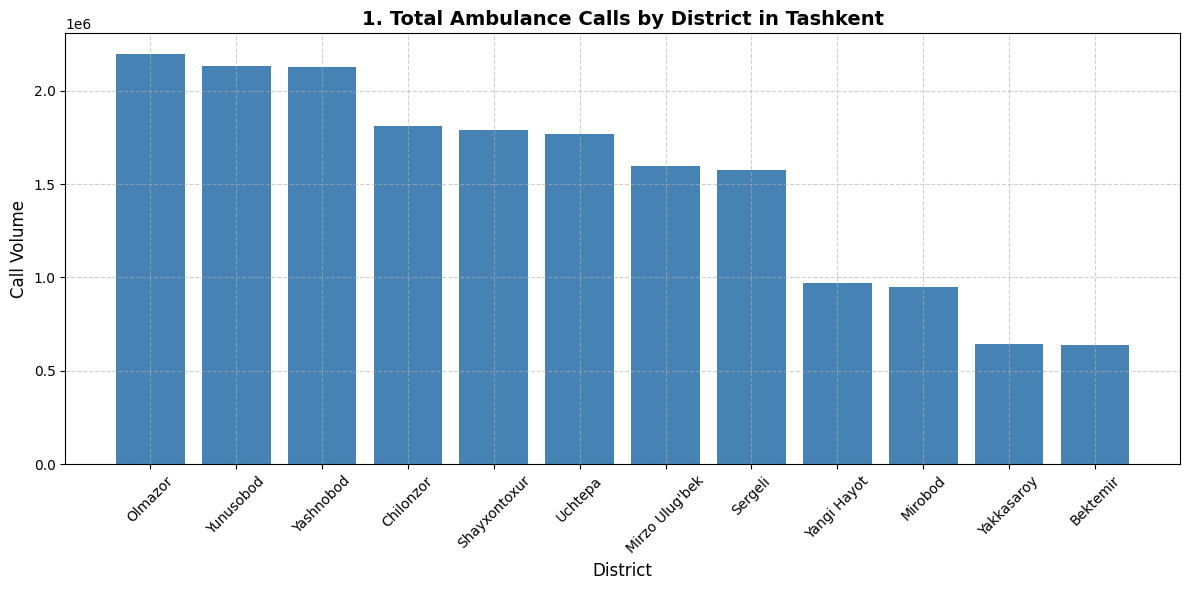

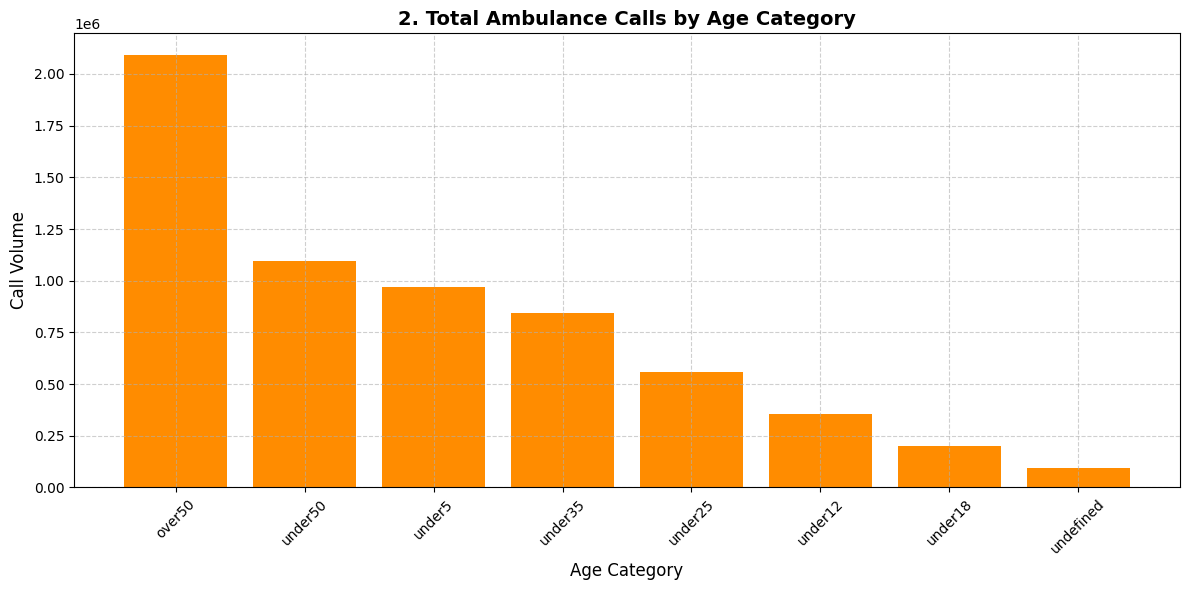

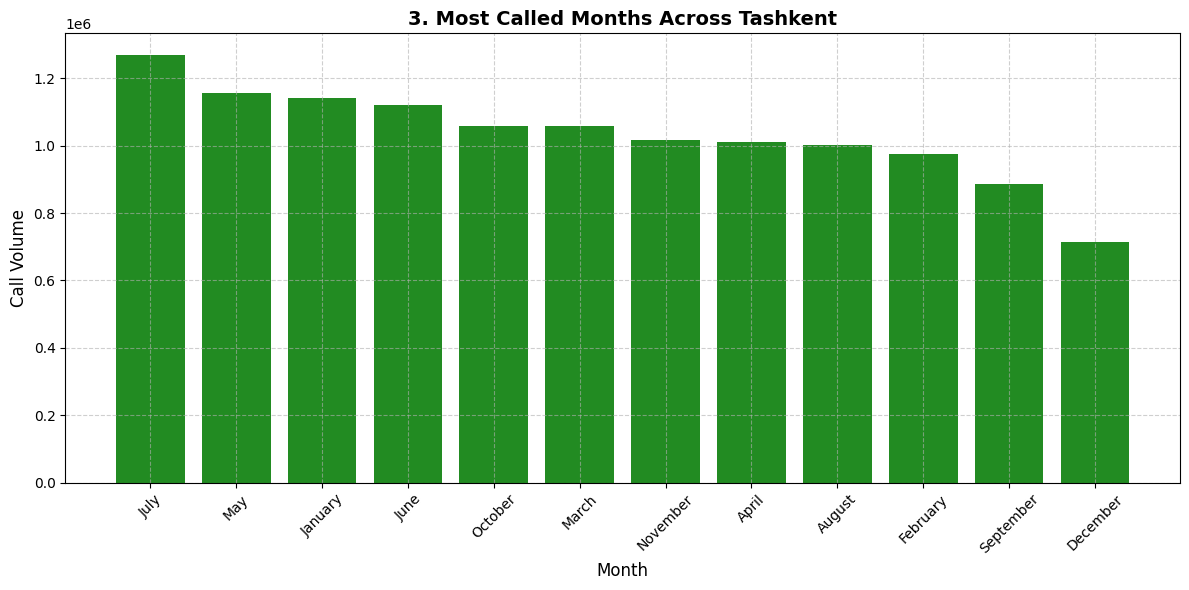

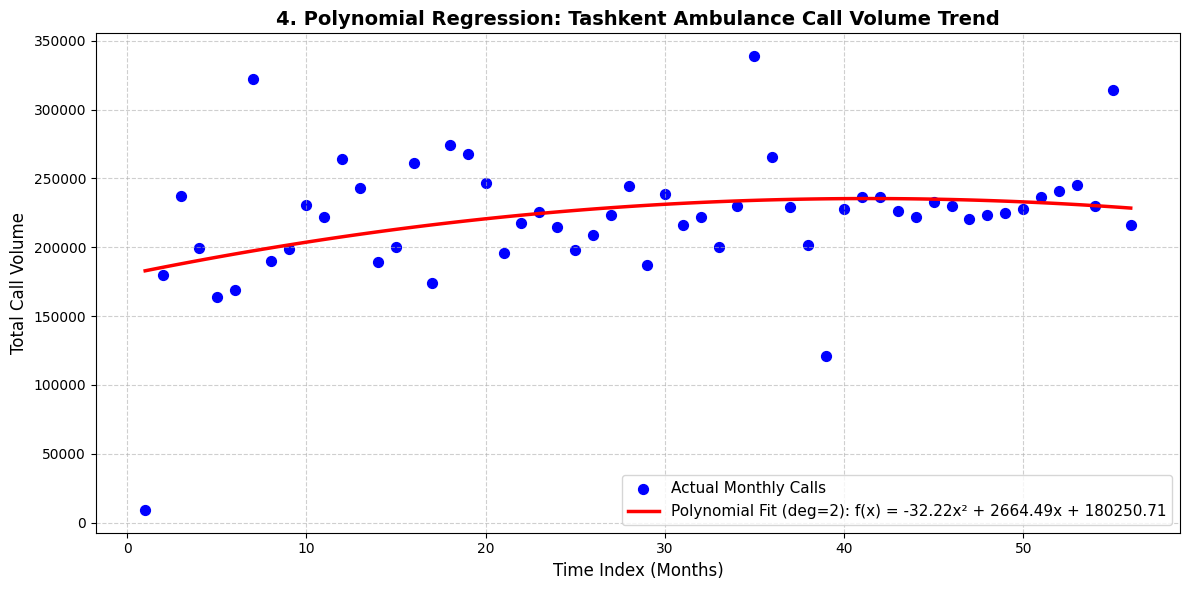

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load data directly from GitHub Raw URL
github_raw_url = "https://raw.githubusercontent.com/Nonamechick/Tashkent-Ambulance-Call-Analysis-and-Prediction/main/monthly_calls_by_agecategory_by_district.xlsx"
df = pd.read_excel(github_raw_url)

# List of Tashkent administrative districts
districts = [
    'Uchtepa', 'Bektemir', 'Yunusobod', "Mirzo Ulug'bek", 'Mirobod',
    'Shayxontoxur', 'Olmazor', 'Sergeli', 'Yakkasaroy', 'Yashnobod',
    'Chilonzor', 'Yangi Hayot'
]

# Rename or select the total column name
col_name = 'Total (Tashkent city)' if 'Total (Tashkent city)' in df.columns else 'Umumiy(Toshkent shahar)'

# ==========================================
# 2. Data Aggregations
# ==========================================

# Chart 1: Total Calls by District
df_district = df[districts].sum().sort_values(ascending=False)

# Chart 2: Total Calls by Age Category (excluding totals/aggregates)
df_age = df[~df['age_category'].str.contains('Umumiy|General', case=False, na=False)]
df_age = df_age.groupby('age_category')[col_name].sum().sort_values(ascending=False)

# Chart 3: Most Called Months (excluding yearly summary rows)
df_month = df[df['month'] != 'Yearly'].groupby('month')[col_name].sum().sort_values(ascending=False)

# Chart 4: Polynomial Regression Data Setup
df_reg = df[df['month'] != 'Yearly'].groupby(['year', 'month'])[col_name].sum().reset_index()
df_reg['Time_Index'] = np.arange(1, len(df_reg) + 1)
x = df_reg['Time_Index'].values
y = df_reg[col_name].values

# Fit Degree 2 Polynomial Model
mymodel = np.poly1d(np.polyfit(x, y, 2))
a, b, c = mymodel.coefficients

print(f"Polynomial Regression Equation: f(x) = {a:.4f}x² + {b:.4f}x + {c:.4f}")

# ==========================================
# 3. Individual Visualizations
# ==========================================

# Graph 1: Calls by District
plt.figure(figsize=(12, 6))
plt.bar(df_district.index, df_district.values, color='steelblue')
plt.title("1. Total Ambulance Calls by District in Tashkent", fontsize=14, fontweight='bold')
plt.xlabel("District", fontsize=12)
plt.ylabel("Call Volume", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Graph 2: Calls by Age Category
plt.figure(figsize=(12, 6))
plt.bar(df_age.index, df_age.values, color='darkorange')
plt.title("2. Total Ambulance Calls by Age Category", fontsize=14, fontweight='bold')
plt.xlabel("Age Category", fontsize=12)
plt.ylabel("Call Volume", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Graph 3: Most Called Months
plt.figure(figsize=(12, 6))
plt.bar(df_month.index, df_month.values, color='forestgreen')
plt.title("3. Most Called Months Across Tashkent", fontsize=14, fontweight='bold')
plt.xlabel("Month", fontsize=12)
plt.ylabel("Call Volume", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Graph 4: Polynomial Regression Curve
plt.figure(figsize=(12, 6))
myline = np.linspace(min(x), max(x), 100)
plt.scatter(x, y, color='blue', s=50, label='Actual Monthly Calls')
plt.plot(myline, mymodel(myline), color='red', linewidth=2.5, label=f'Polynomial Fit (deg=2): f(x) = {a:.2f}x² + {b:.2f}x + {c:.2f}')
plt.title("4. Polynomial Regression: Tashkent Ambulance Call Volume Trend", fontsize=14, fontweight='bold')
plt.xlabel("Time Index (Months)", fontsize=12)
plt.ylabel("Total Call Volume", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()